In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')
import altair as alt # pacote para outros tipos de gráficos

## AA
from sklearn.cluster import KMeans

# Exemplo simples: 6 pessoas (idade, renda)

In [2]:
dados=pd.DataFrame({'renda': [9.6,8.4,2.4,18.2,3.9,6.4],
                    'idade': [28, 31, 42, 38, 25, 41]})
dados

,renda,idade
0,9.6,28
1,8.4,31
2,2.4,42
3,18.2,38
4,3.9,25
5,6.4,41


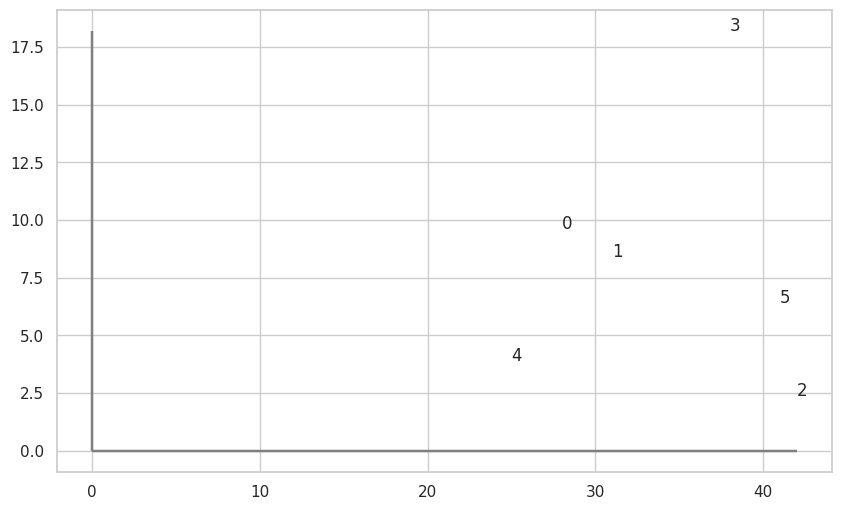

In [3]:
# diagrama de dispersão das variáveis originais
fig, ax = plt.subplots()
fig.set_size_inches(10,6)
ax.scatter(dados.idade,dados.renda,s=0)
for i, txt in enumerate (dados.index):
  ax.annotate(txt, (dados.idade[i], dados.renda[i]))
  plt.hlines(0,0,dados.idade.max(),color='gray')
  plt.vlines(0,0,dados.renda.max(),color='gray');

Se outro método de agrupamento for escolhido, basta alterar o parâmetro 'method' na função linkage na célula abaixo:

In [4]:
X = dados

# K-médias

Como é preciso decidir o número de grupos antes de aplicar o método das k-médias, usaremos como critério o número de grupos definido a partir da observação do dendrograma. MAs outro método que pode auxiliar é o gráfico k x SQDG:

## Gráfico k x SQDG

Auxilia a decidir em quantos grupos dividir os dados usando o método das k-médias. Procurar pelo 'cotovelo' (ponto a partir do qual a queda da SQDG é menor).

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

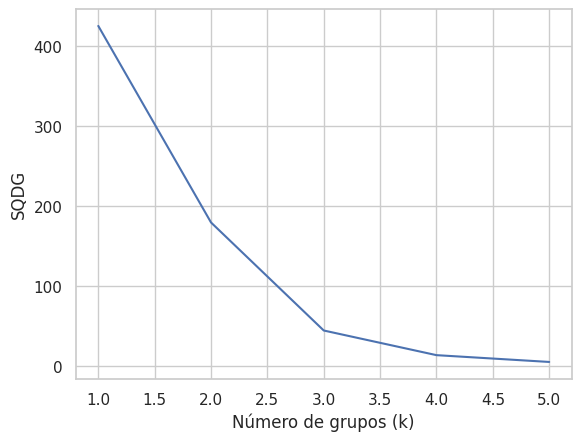

In [6]:
# SQDG
SQDG = {}
for k in range(1,6):
  kmeans=KMeans(n_clusters=k, max_iter=1000).fit(dados)
  dados['grupo']=kmeans.labels_
  SQDG[k]= kmeans.inertia_  # Inertia: soma das distâncias das observações ao centro mais próximo
plt.figure
plt.plot(list(SQDG.keys()),list(SQDG.values()))
plt.xlabel('Número de grupos (k)')
plt.ylabel('SQDG');
plt.show()

Por meio desse gráfico diríamos que há 3 grupos, pois a queda de 3 para 4 é pequena.
Porém, como o conjunto de dados é muito pequeno (n=6), ficaremos com 2 grupos.
Além disso, a partir de dendrograma obtido pelo método de Ward, escolhemos k=2 grupos.

In [7]:
# redefinindo X
X = dados

In [8]:
# número de grupos sugerido pelo dendrograma
k = 2

In [9]:
kmeans=KMeans(n_clusters=k,random_state=10).fit(X)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [12]:
# incluir no Dataframe de dados as informações sobre a qual grupo cada pessoa pertence
dados['grupo']=kmeans.labels_
dados

,renda,idade,grupo
0,9.6,28,0
1,8.4,31,0
2,2.4,42,1
3,18.2,38,1
4,3.9,25,0
5,6.4,41,1


In [13]:
# média dos grupos - todas as variáveis
# inclusive as não utilizadas para agrupar
dados.groupby('grupo').mean()

,renda,idade
grupo,,
0,7.3,28.000000
1,9.0,40.333333


In [14]:
# mediana das variáveis para cada grupo
dados.groupby('grupo').median()

,renda,idade
grupo,,
0,8.4,28.0
1,6.4,41.0


Interpretação dos grupos:
grupo 0: renda maior, maior idade.
grupo 1: renda menor, menor idade.

In [15]:
# observações dos grupos:
grupo0=dados.query('grupo==0').index
list(grupo0)

[0, 1, 4]

In [16]:
# observações dos grupos:
grupo1=dados.query('grupo==1').index
list(grupo1)

[2, 3, 5]